#  Korku Yazarını Tanıma (Spooky Author Identification)
Üç ünlü korku yazarının eserlerinden alınmış **cümleler** veriliyor. Bir cümlenin hangi yazara ait olduğunu tahmin etmeye çalışıyoruz:
EAP: Edgar Allan Poe
HPL: H. P. Lovecraft
MWS: Mary Wollstonecraft Shelley (Frankenstein'ın yazarı)
Yazarların kelime seçimi, cümle kuruşu ve noktalama alışkanlıkları farklı. Bu notebook'ta bu farkları inceleyeceğiz.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline, make_union
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss, accuracy_score, confusion_matrix

In [2]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
sample = pd.read_csv('sample_submission.csv')

In [3]:
train.shape

(19579, 3)

In [4]:
test.shape

(8392, 2)

In [5]:
train.isnull().sum()

id        0
text      0
author    0
dtype: int64

In [6]:
test.isnull().sum()

id      0
text    0
dtype: int64

In [7]:
train.head()

,id,text,author
0,id26305,"This process, however, afforded me no means of...",EAP
1,id17569,It never once occurred to me that the fumbling...,HPL
2,id11008,"In his left hand was a gold snuff box, from wh...",EAP
3,id27763,How lovely is spring As we looked from Windsor...,MWS
4,id12958,"Finding nothing else, not even gold, the Super...",HPL


In [8]:
print('Yazar dağılımı:')
print(train.author.value_counts())
print()
print(train.author.value_counts(normalize=True).round(3))

Yazar dağılımı:
author
EAP    7900
MWS    6044
HPL    5635
Name: count, dtype: int64

author
EAP    0.403
MWS    0.309
HPL    0.288
Name: proportion, dtype: float64


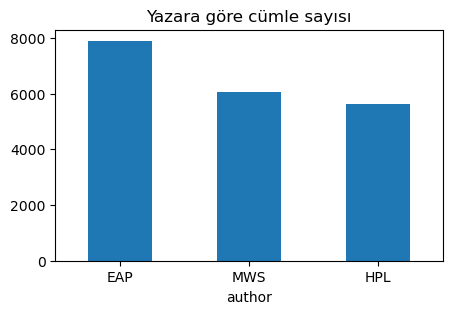

In [9]:
train.author.value_counts().plot(kind='bar', figsize=(5, 3))
plt.title('Yazara göre cümle sayısı')
plt.xticks(rotation=0);

In [10]:
for yazar in ['EAP', 'HPL', 'MWS']:
    print(yazar, ':', train[train.author == yazar].text.iloc[0][:140])

EAP : This process, however, afforded me no means of ascertaining the dimensions of my dungeon; as I might make its circuit, and return to the poi
HPL : It never once occurred to me that the fumbling might be a mere mistake.
MWS : How lovely is spring As we looked from Windsor Terrace on the sixteen fertile counties spread beneath, speckled by happy cottages and wealth


In [11]:
train['kelime_sayisi'] = train.text.str.split().str.len()
ozellikler = pd.DataFrame({
    'kelime': train.groupby('author').kelime_sayisi.mean(),
    'virgül (,)': train.groupby('author').text.apply(lambda x: x.str.count(',').mean()),
    'noktalı virgül (;)': train.groupby('author').text.apply(lambda x: x.str.count(';').mean()),
    'tırnak (")': train.groupby('author').text.apply(lambda x: x.str.count('"').mean()),
    "kesme (')": train.groupby('author').text.apply(lambda x: x.str.count("'").mean()),
})
print(ozellikler.round(3))

        kelime  virgül (,)  noktalı virgül (;)  tırnak (")  kesme (')
author                                                               
EAP     25.442       2.227               0.171       0.378      0.169
HPL     27.800       1.523               0.203       0.091      0.303
MWS     27.417       1.993               0.440       0.243      0.079


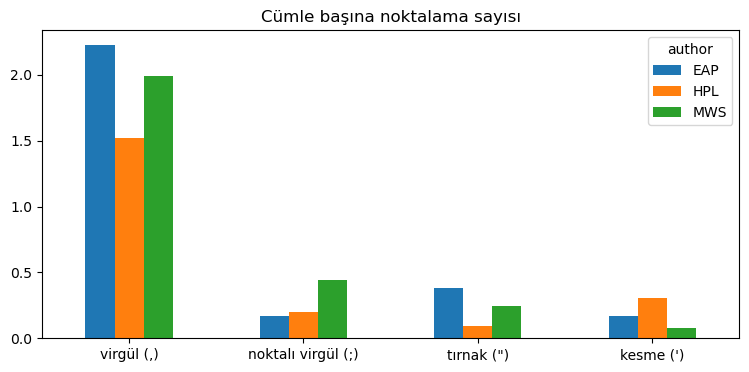

In [12]:
ozellikler.drop(columns='kelime').T.plot(kind='bar', figsize=(9, 4))
plt.title('Cümle başına noktalama sayısı')
plt.xticks(rotation=0);

Yazarların alışkanlıkları gerçekten farklı:
Mary Shelley noktalı virgülü diğerlerinin yaklaşık iki katı kullanıyor.
Poe çift tırnağı (diyalog) çok daha sık kullanıyor.
Lovecraft kesme işaretini çok daha sık kullanıyor.
Cümle uzunlukları birbirine yakın: yazarı ayırmakta uzunluk işe yaramaz.
Bu yüzden sadece kelimelere değil, noktalamaya ve harf gruplarına da bakmak faydalı olabilir.

In [13]:
egitim, dogrulama = train_test_split(train, test_size=0.2, stratify=train.author, random_state=42)
yazarlar = ['EAP', 'HPL', 'MWS']
y_e = egitim.author.map({a: i for i, a in enumerate(yazarlar)}).values
y_d = dogrulama.author.map({a: i for i, a in enumerate(yazarlar)}).values
print('eğitim:', egitim.shape, '| doğrulama:', dogrulama.shape)

kelime_deseni = r"(?u)\b[\w']+\b"
sonuclar = {}

def dene(isim, vektorlestirici, model):
    pipe = Pipeline([('vec', vektorlestirici), ('model', model)])
    pipe.fit(egitim.text, y_e)
    olasilik = pipe.predict_proba(dogrulama.text)
    sonuclar[isim] = {'Log loss': log_loss(y_d, olasilik), 'Accuracy': accuracy_score(y_d, olasilik.argmax(1))}
    print(isim, '->', {k: round(float(v), 4) for k, v in sonuclar[isim].items()})
    return pipe, olasilik

eğitim: (15663, 4) | doğrulama: (3916, 4)


In [14]:
oranlar = np.bincount(y_e) / len(y_e)
olasilik = np.tile(oranlar, (len(y_d), 1))
sonuclar['Sadece yazar oranları (referans)'] = {'Log loss': log_loss(y_d, olasilik), 'Accuracy': accuracy_score(y_d, olasilik.argmax(1))}
print({k: round(float(v), 4) for k, v in sonuclar['Sadece yazar oranları (referans)'].items()})

{'Log loss': 1.0875, 'Accuracy': 0.4035}


In [15]:
_ = dene('Naive Bayes (Bag of Words)', CountVectorizer(token_pattern=kelime_deseni), MultinomialNB(alpha=0.5))

Naive Bayes (Bag of Words) -> {'Log loss': 0.4937, 'Accuracy': 0.8404}


In [16]:
_ = dene('Logistic Regression (TF-IDF 1-2 kelime)',
         TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, token_pattern=kelime_deseni),
         LogisticRegression(C=10, max_iter=2000))

Logistic Regression (TF-IDF 1-2 kelime) -> {'Log loss': 0.4282, 'Accuracy': 0.8386}


In [17]:
_ = dene('Logistic Regression (TF-IDF harf grupları)',
         TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), sublinear_tf=True),
         LogisticRegression(C=10, max_iter=2000))

Logistic Regression (TF-IDF harf grupları) -> {'Log loss': 0.4099, 'Accuracy': 0.846}


In [18]:
_ = dene('Logistic Regression (kelime + harf grupları)',
         make_union(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, token_pattern=kelime_deseni),
                    TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), sublinear_tf=True)),
         LogisticRegression(C=10, max_iter=2000))

Logistic Regression (kelime + harf grupları) -> {'Log loss': 0.3713, 'Accuracy': 0.8608}


In [19]:
nb_pipe, nb_olasilik = dene('Naive Bayes (TF-IDF 1-2 kelime)',
                            TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, token_pattern=kelime_deseni, min_df=1),
                            MultinomialNB(alpha=0.02))

Naive Bayes (TF-IDF 1-2 kelime) -> {'Log loss': 0.3648, 'Accuracy': 0.8573}


In [20]:
tablo = pd.DataFrame(sonuclar).T.sort_values('Log loss').round(4)
print(tablo)

                                              Log loss  Accuracy
Naive Bayes (TF-IDF 1-2 kelime)                 0.3648    0.8573
Logistic Regression (kelime + harf grupları)    0.3713    0.8608
Logistic Regression (TF-IDF harf grupları)      0.4099    0.8460
Logistic Regression (TF-IDF 1-2 kelime)         0.4282    0.8386
Naive Bayes (Bag of Words)                      0.4937    0.8404
Sadece yazar oranları (referans)                1.0875    0.4035


Text(0.5, 1.0, 'Doğrulama log loss (küçük iyi)')

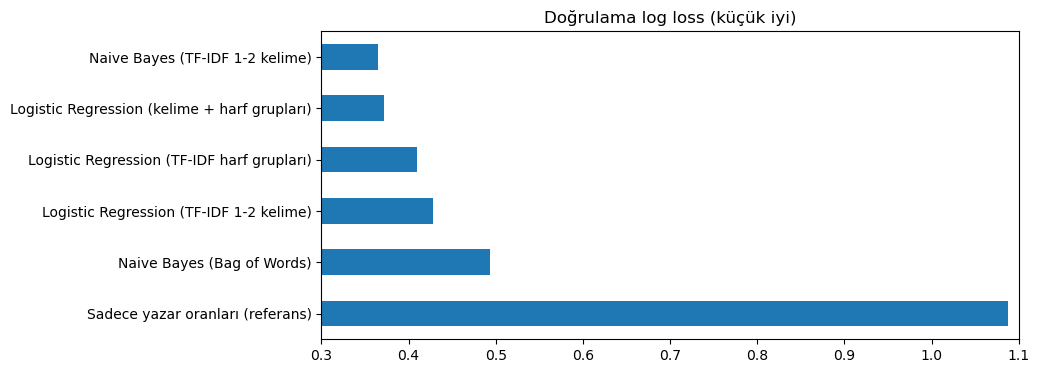

In [21]:
tablo['Log loss'].sort_values(ascending=False).plot(kind='barh', figsize=(9, 4), xlim=(0.3, 1.1))
plt.title('Doğrulama log loss (küçük iyi)')

In [22]:
vec = nb_pipe.named_steps['vec']
nb = nb_pipe.named_steps['model']
X_e = vec.transform(egitim.text)
yeterli = np.asarray((X_e > 0).sum(axis=0)).ravel() >= 15       
kelimeler = vec.get_feature_names_out()
for i, yazar in enumerate(yazarlar):
    diger = np.delete(nb.feature_log_prob_, i, axis=0).mean(axis=0)
    fark = np.where(yeterli, nb.feature_log_prob_[i] - diger, -np.inf)
    print(yazar, ':', list(kelimeler[np.argsort(fark)[-12:][::-1]]))

EAP : ['dupin', 'the balloon', 'marie', 'jupiter', 'chess', 'said dupin', 'the automaton', 'diddler', 'legrand', 'diddle', 'monsieur', 'prefect']
HPL : ['gilman', 'innsmouth', 'arkham', 'armitage', 'whateley', 'folk', 'because of', 'attic', 'brown', 'aout', 'reef', 'iranon']
MWS : ['perdita', 'adrian', 'idris', 'windsor', 'raymond', 'endeavoured', 'endeavoured to', 'justine', 'clara', 'felix', 'evadne', 'clerval']


Yazarı en çok ayıran kelimelerin çoğu **karakter ve yer adları**: Poe'da `dupin`, Lovecraft'ta `innsmouth` ve `arkham`, Shelley'de `perdita` ve `idris` gibi. Yani model biraz da "hangi hikâyeden olduğunu" ezberliyor. Bu, aynı eserlerden alınan test cümlelerinde iyi çalışıyor ama yazarın başka bir eserinden gelen cümlelerde zayıf kalabileceğini gösteriyor.

In [23]:
tahmin = nb_olasilik.argmax(1)
print('Karışıklık tablosu (satır = gerçek yazar, sütun = tahmin):')
print(pd.DataFrame(confusion_matrix(y_d, tahmin), index=yazarlar, columns=yazarlar))
print()
for i, yazar in enumerate(yazarlar):
    print(f'{yazar}: doğru bilinme oranı %{(tahmin[y_d == i] == i).mean() * 100:.1f}')

Karışıklık tablosu (satır = gerçek yazar, sütun = tahmin):
      EAP  HPL   MWS
EAP  1383   71   126
HPL   130  928    69
MWS   111   52  1046

EAP: doğru bilinme oranı %87.5
HPL: doğru bilinme oranı %82.3
MWS: doğru bilinme oranı %86.5


In [24]:
def kirp(olasilik, eps):
    p = np.clip(olasilik, eps, 1)
    return p / p.sum(axis=1, keepdims=True)

kirpma = {eps: log_loss(y_d, kirp(nb_olasilik, eps)) for eps in [0, 1e-4, 1e-3, 3e-3, 1e-2, 3e-2]}
for eps, ll in kirpma.items():
    print(f'{eps:<7} log loss: {ll:.4f}')
en_iyi_ll = min(kirpma.values())
EPS = max(e for e, ll in kirpma.items() if ll <= en_iyi_ll + 0.0005)  
print()
print('Seçilen :', EPS)

0       log loss: 0.3648
0.0001  log loss: 0.3648
0.001   log loss: 0.3648
0.003   log loss: 0.3650
0.01    log loss: 0.3682
0.03    log loss: 0.3822

Seçilen : 0.003


In [25]:
y_tum = train.author.map({a: i for i, a in enumerate(yazarlar)}).values
model = Pipeline([('vec', TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, token_pattern=kelime_deseni)),
                  ('model', MultinomialNB(alpha=0.02))])
model.fit(train.text, y_tum)

test_olasilik = kirp(model.predict_proba(test.text), EPS)
sonuc = pd.DataFrame(test_olasilik, columns=yazarlar)
sonuc.insert(0, 'id', test.id.values)
sonuc.to_csv('sonuc1.csv', index=False)
print(sonuc.shape)
sonuc.head()

(8392, 4)


,id,EAP,HPL,MWS
0,id02310,0.034365,0.006126,0.959509
1,id24541,0.981092,0.015047,0.003861
2,id00134,0.009695,0.984924,0.005381
3,id27757,0.460857,0.531982,0.007161
4,id04081,0.637500,0.255283,0.107216


In [26]:
print('sütunlar sample ile aynı mı:', list(sonuc.columns) == list(sample.columns))
print('id\'ler aynı mı           :', (sonuc.id.values == sample.id.values).all())
print('satır toplamı 1 mi        :', np.allclose(sonuc[yazarlar].sum(axis=1), 1))
print('boş değer var mı          :', sonuc[yazarlar].isna().any().any())
print()
print('Test tahmin dağılımı (en olası yazar):')
print(sonuc[yazarlar].idxmax(axis=1).value_counts(normalize=True).round(3))

sütunlar sample ile aynı mı: True
id'ler aynı mı           : True
satır toplamı 1 mi        : True
boş değer var mı          : False

Test tahmin dağılımı (en olası yazar):
EAP    0.403
MWS    0.329
HPL    0.268
Name: proportion, dtype: float64


In [27]:
denemeler = ['It was a dark and stormy night, and the raven tapped upon my chamber door.',
             'The ancient horror crept from the sunken city beneath the black and nameless sea.',
             'I beheld the wretch whom I had created; he looked at me with eyes full of sorrow.']
for c in denemeler:
    p = model.predict_proba([c])[0]
    print({y: round(float(v), 2) for y, v in zip(yazarlar, p)}, '|', c)

{'EAP': 0.27, 'HPL': 0.6, 'MWS': 0.12} | It was a dark and stormy night, and the raven tapped upon my chamber door.
{'EAP': 0.01, 'HPL': 0.99, 'MWS': 0.0} | The ancient horror crept from the sunken city beneath the black and nameless sea.
{'EAP': 0.03, 'HPL': 0.03, 'MWS': 0.93} | I beheld the wretch whom I had created; he looked at me with eyes full of sorrow.


In [28]:
with open('model.pkl', 'wb') as f:
    pickle.dump(model, f)
print('model.pkl kaydedildi')

model.pkl kaydedildi


Yazarlar sadece kelimeleriyle değil, noktalama ve yazım alışkanlıklarıyla da ayrışıyor: Mary Shelley noktalı virgülü, Poe çift tırnağı, Lovecraft kesme işaretini daha çok kullanıyor. Bu yüzden metni hiç temizlemedik, büyük harf ve noktalamayı olduğu gibi bıraktık.
Kelime ve harf gruplarını birleştirmek ve TF-IDF kullanmak Bag of Words'e göre belirgin iyileştirme sağladı. Naive Bayes en iyi log loss'u verdi ve çok hızlı.